# Assignment 05: Time patterns and unusual increases

**Overall purpose:** Answer the five crime-data questions on slide 11 using reproducible topic modeling and evidence-based report analysis. Your section must connect to the shared final report table and the main workstation.

## Shared rules: read before writing code

1. **Claim one assignment.** Add your name and reviewer below, then tell the group. These six notebooks are roles, not six tasks for each person.
2. **Use the shared files.** The original Parquet and shared/reports_base.parquet are read-only inputs. The base adds stable report_id values but does not clean or classify anything.
3. **Keep report_id.** Never recreate IDs after filtering, sorting or resetting an index. Join results using report_id with merge validation. URL is not a unique ID: some URLs repeat.
4. **Use one prepared version.** Member 1 must publish outputs/member_01/reports_prepared.parquet before final modeling. Preserve all source rows and mark exclusions. Everyone records that file's checksum in run_metadata.json. Prototype results on the base are exploratory and must be rerun on the agreed prepared file.
5. **Preserve alignment.** Build each text list and embedding matrix from the same filtered DataFrame in the same order. Never filter/sort text and embeddings separately.
6. **Separate analysis from evidence.** Write short code cells, show readable tables/plots, and explain actual outputs. Do not invent findings, silently fill missing districts, or treat a colored cluster plot as proof of meaningful crime types.
7. **Export to your own folder.** outputs/member_XX holds submissions; figures/member_XX holds readable figures. templates/member_XX contains empty examples and is never a finished submission.
8. **Finish with a peer review.** Everyone contributes their section, interpretation and sample reading. Member 6 coordinates validation; they do not write the entire group project.

**Your name:** Ghofran Mahmoud (Ghod)  
**Peer reviewer:** ______  
**Status:** In progress (all-report analysis done; category analysis waits for Member 6)  
**Prepared input version/checksum:** bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139


## Setup and input check

Keep this notebook inside team_notebooks, or beside the shared folder. Copy the project folder when sharing it; the notebook alone does not contain the dataset.

In [1]:
from pathlib import Path
import pandas as pd
import json

In [2]:
project_folder = Path.cwd()
if not (project_folder / "shared").exists():
    project_folder = project_folder.parent

assert (project_folder / "shared/source_manifest.json").exists(), "Open the notebook from the shared project folder."

In [3]:
output_folder = project_folder / "outputs/member_05"
figure_folder = project_folder / "figures/member_05"
output_folder.mkdir(parents=True, exist_ok=True)
figure_folder.mkdir(parents=True, exist_ok=True)

In [4]:
text_columns = ["report_id", "date_posted", "title_en", "description_en", "district", "url"]
reports_base = pd.read_parquet(project_folder / "shared/reports_base.parquet", columns=text_columns)
assert reports_base["report_id"].is_unique
print("Base reports:", len(reports_base))
reports_base[["report_id", "date_posted", "title_en", "district"]].head(3)

Base reports: 5126


,report_id,date_posted,title_en,district
0,BR000000,2026-09-03,Police release wanted photo after shooting in ...,Woltmershausen
1,BR000001,2026-09-03,Burglary in Bar - Police Catch Perpetrators,Ostertor
2,BR000002,2026-09-02,Paint vandalism at high school,Horn


In [5]:
prepared_path = project_folder / "outputs/member_01/reports_prepared.parquet"
if prepared_path.exists():
    prepared_columns = text_columns + ["district_clean", "include_in_analysis", "exclusion_reason"]
    reports = pd.read_parquet(prepared_path, columns=prepared_columns)
    print("Prepared input available. Check its version before modeling.")
else:
    print("Preparation pending: final modeling and group analysis must wait for Member 1.")

Prepared input available. Check its version before modeling.


### Packages

Use the agreed group environment. From the project folder, the setup command is `python -m pip install -r requirements.txt`. Do this only when preparing the modeling environment. The skeleton uses pandas/pyarrow; BERTopic, UMAP and HDBSCAN are not installed in the environment used to check these starter notebooks. No algorithm has been run yet.

## Things to note throughout the project

- Count reports, not confirmed incidents or individual victims. One report can discuss several events or offenses. Treat the unit consistently.
- date_posted is a publication date. The first/last years and boundary months are partial; the source's collection coverage is not established by its date range alone.
- District labels include literal None and potentially different geographic levels. Unknown district reports still matter for citywide totals; district rankings need a consistent reviewed geography.
- Categories such as Theft, Traffic-related, Assault, Burglary, Fraud and Drug-related are candidate names, not predetermined model results. Include an Unknown/Unclear option and a documented non-crime/report-type category where needed.
- A topic is a group of similar reports, not automatically a legal crime category. Several topics can map to one category; mixed topics may need a per-report review.
- Use one primary category per report for the main count tables. If the group later adopts multiple labels, document that totals can exceed the report count and rebuild all comparisons consistently.
- The source includes descriptions of harmful events. Keep relevant evidence brief in outputs, avoid unnecessary identifying details, and use report IDs/source URLs for traceability.
- No API calls, paid services, extra scraping or AI-generated embeddings are needed to start. Optional AI-assisted elderly detection needs a separate agreed method and human verification.


## Purpose and dependencies

You answer Questions 2 and 3: how category/district report counts change over time, whether seasonal peaks recur, and where short-term increases deserve investigation.

**Final inputs:** the frozen prepared dataset and Member 6's approved report_categories.csv/selected_model.json. You can audit date coverage and design plots before labels are ready. Do not build final charts from your own category guesses or a different candidate model.

### 1. Join dates, districts and approved categories

Merge by report_id with validate="one_to_one". Check prepared/category checksums, ID sets and include_in_analysis. Keep Unknown categories/districts visible in totals, and state when a chart excludes them. Check date_posted is datetime. The publication date is the date variable available for these questions.

In [6]:
import hashlib, platform
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import poisson, kruskal, mannwhitneyu, kendalltau
from dateutil.easter import easter
from IPython.display import display

# The agreed prepared version published by Member 1. Change only after group agreement.
EXPECTED_PREPARED_SHA256 = "bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139"

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

manifest = json.loads((project_folder / "shared/source_manifest.json").read_text(encoding="utf-8"))
contracts = json.loads((project_folder / "artifact_contracts.json").read_text(encoding="utf-8"))
schemas = contracts["roles"]["member_05"]["csv_schemas"]

# One chart style for every figure in this notebook.
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
BLUE, ORANGE, LIGHT_BLUE = "#2a78d6", "#eb6834", "#a9c8ef"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": GRID, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})
figure_files = []

def save_figure(fig, name):
    fig.savefig(figure_folder / name, dpi=160, bbox_inches="tight")
    figure_files.append(name)
    plt.show()
    plt.close(fig)

In [7]:
# Verify the prepared file before using it.
prepared_sha256 = sha256(prepared_path)
preparation_metadata = json.loads((prepared_path.parent / "run_metadata.json").read_text(encoding="utf-8"))
assert prepared_sha256 == EXPECTED_PREPARED_SHA256, "Prepared file differs from the agreed version: check with Member 1."
assert preparation_metadata["prepared_sha256"] == prepared_sha256
assert sha256(project_folder / manifest["base_file"]) == manifest["base_sha256"]

reports = pd.read_parquet(prepared_path, columns=[
    "report_id", "date_posted", "title_en", "district", "district_clean",
    "include_in_analysis", "exclusion_reason", "url"])
assert len(reports) == manifest["row_count"] == 5126 and reports["report_id"].is_unique
assert set(reports["report_id"]) == set(reports_base["report_id"])
assert pd.api.types.is_datetime64_any_dtype(reports["date_posted"]) and reports["date_posted"].notna().all()
assert reports["include_in_analysis"].dtype == bool
print("Prepared SHA-256 verified:", prepared_sha256)

Prepared SHA-256 verified: bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139


In [8]:
# Approved categories from Member 6 are used only when they are approved for this prepared version.
PENDING_LABEL = "All reports (categories pending)"
ALL_LABEL = "All reports"
category_folder = project_folder / "outputs/member_06"
categories_path = category_folder / "report_categories.csv"
selection_path = category_folder / "selected_model.json"

CATEGORY_MODE, report_categories_sha256, selected_model_id = False, None, None
category_check = "report_categories.csv or selected_model.json not published yet"
if categories_path.exists() and selection_path.exists():
    selection = json.loads(selection_path.read_text(encoding="utf-8"))
    report_categories_sha256 = sha256(categories_path)
    if selection.get("status") != "approved":
        category_check = "selected_model.json is not approved"
    elif selection.get("prepared_sha256") != prepared_sha256:
        category_check = "categories were built on a different prepared version"
    elif selection.get("report_categories_sha256") != report_categories_sha256:
        category_check = "report_categories.csv checksum differs from selected_model.json"
    else:
        CATEGORY_MODE, selected_model_id = True, selection["model_id"]
        category_check = "approved categories validated"

if CATEGORY_MODE:
    categories = pd.read_csv(categories_path, dtype=str, keep_default_na=False)
    assert categories.columns.tolist() == contracts["roles"]["member_06"]["csv_schemas"]["report_categories.csv"]
    labeled = reports.merge(categories[["report_id", "crime_category", "category_status"]],
                            on="report_id", how="left", validate="one_to_one", indicator=True)
    assert labeled["_merge"].eq("both").all(), "Some reports have no category row."
    labeled = labeled.drop(columns="_merge")
    assert labeled.loc[~labeled["include_in_analysis"], "category_status"].eq("excluded").all()
else:
    report_categories_sha256 = None
    labeled = reports.copy()
    labeled["crime_category"] = PENDING_LABEL
    labeled["category_status"] = "pending"

cohort = labeled.loc[labeled["include_in_analysis"]].copy()
assert len(cohort) == int(preparation_metadata["counts"]["included"]) == 5124

print("Category check:", category_check)
pd.Series({
    "Base reports": len(labeled),
    "Excluded (Member 1 duplicates)": int((~labeled["include_in_analysis"]).sum()),
    "Included reports analysed": len(cohort),
    "Included with Unknown district": int(cohort["district_clean"].eq("Unknown").sum()),
    "Crime categories in use": cohort["crime_category"].nunique(),
}, name="value").to_frame()

Category check: report_categories.csv or selected_model.json not published yet


,value
Base reports,5126
Excluded (Member 1 duplicates),2
Included reports analysed,5124
Included with Unknown district,975
Crime categories in use,1


**Explain your output:**

- **Observed:** the prepared file matches the agreed checksum. All 5,126 report IDs are present; 5,124 are included and the 2 duplicates flagged by Member 1 are left out. 975 included reports (19%) have an Unknown district.
- **Why it matters:** every count below uses exactly the same cohort as Members 1 and 6, so totals can be reconciled across sections.
- **Uncertain:** Member 6 has not published approved categories yet, so every report currently carries the label "All reports (categories pending)". The category code in Sections 3 to 5 runs automatically once `report_categories.csv` and an approved `selected_model.json` exist. Rerun the notebook then and update these interpretations.

### 2. Define the time window and counting rules

Inspect yearly/monthly coverage before summarizing. The dataset starts 14 July 2019 and ends 3 September 2026. Mark partial boundary months/years. Do not compare a partial year with a full year as if their exposure were equal. Missing months are not automatically evidence of zero crime or complete collection; state any zero-filling assumption.

In [9]:
# Monthly report counts over the full publication range, zero-filled only to expose gaps.
cohort["month"] = cohort["date_posted"].dt.to_period("M")
all_months = pd.period_range(cohort["month"].min(), cohort["month"].max(), freq="M")
monthly_total = cohort.groupby("month").size().reindex(all_months, fill_value=0)

observed = monthly_total.gt(0)
gap_months = monthly_total.index[~observed]
# A month is partial when collection starts or stops inside it.
partial_months = {all_months[0], all_months[-1]}
for position in range(1, len(all_months) - 1):
    if observed.iloc[position] and (not observed.iloc[position - 1] or not observed.iloc[position + 1]):
        partial_months.add(all_months[position])
complete_months = [m for m in all_months if observed[m] and m not in partial_months]

CITY_START, END_MONTH = min(complete_months), max(complete_months)
assert all(observed[m] for m in pd.period_range(CITY_START, END_MONTH, freq="M")), "Gap inside the analysis window."
print("First / last publication date:", cohort["date_posted"].min().date(), "/", cohort["date_posted"].max().date())
print("Collection gap (no reports):", gap_months.min(), "to", gap_months.max(), f"({len(gap_months)} months)")
print("Partial months:", ", ".join(str(m) for m in sorted(partial_months)))
print("Citywide analysis window:", CITY_START, "to", END_MONTH,
      f"({len(pd.period_range(CITY_START, END_MONTH, freq='M'))} complete months)")

First / last publication date: 2019-07-14 / 2026-09-03
Collection gap (no reports): 2019-08 to 2020-06 (11 months)
Partial months: 2019-07, 2020-07, 2026-09
Citywide analysis window: 2020-08 to 2026-08 (73 complete months)


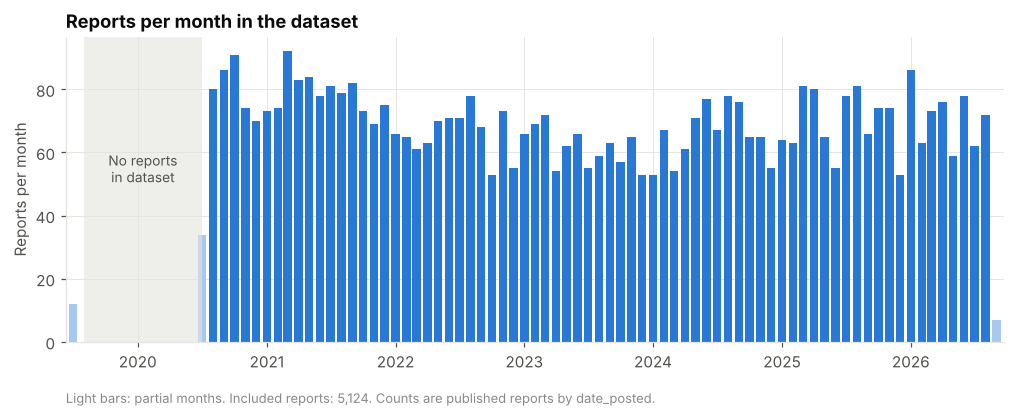

In [10]:
# Figure 1: what the data covers.
fig, ax = plt.subplots(figsize=(11, 3.6))
x = all_months.to_timestamp()
colors = [LIGHT_BLUE if m in partial_months else BLUE for m in all_months]
ax.bar(x, monthly_total.values, width=24, color=colors)
gap_start, gap_end = gap_months.min().to_timestamp(), (gap_months.max() + 1).to_timestamp()
ax.axvspan(gap_start, gap_end, color=GRID, alpha=0.6, lw=0)
ax.text(gap_start + (gap_end - gap_start) / 2, monthly_total.max() * 0.55,
        "No reports\nin dataset", ha="center", color=INK2, fontsize=9)
ax.set(title="Reports per month in the dataset", ylabel="Reports per month",
       xlim=(x[0] - pd.Timedelta(days=20), x[-1] + pd.Timedelta(days=20)))
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.text(0, -0.2, f"Light bars: partial months. Included reports: {len(cohort):,}. Counts are published reports by date_posted.",
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
save_figure(fig, "fig1_monthly_coverage.png")

In [11]:
# Reports per complete month by year, so partial years are not compared with full years.
window = cohort.loc[cohort["month"].between(CITY_START, END_MONTH)]
by_year = window.groupby(window["month"].dt.year).agg(reports=("report_id", "size"),
                                                      complete_months=("month", "nunique"))
by_year["reports_per_month"] = (by_year["reports"] / by_year["complete_months"]).round(1)
display(by_year)

# Publication weekday: the press office publishes fewer releases at weekends.
weekday = cohort["date_posted"].dt.day_name().value_counts().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
print("Reports by publication weekday:"); print(weekday.to_string())
print("Maximum reports on a single day:", cohort["date_posted"].value_counts().max())

,reports,complete_months,reports_per_month
month,,,
2020,401,5,80.2
2021,943,12,78.6
2022,794,12,66.2
2023,741,12,61.8
2024,789,12,65.8
2025,834,12,69.5
2026,569,8,71.1


Reports by publication weekday:
date_posted
Monday       877
Tuesday      738
Wednesday    781
Thursday     810
Friday       880
Saturday     353
Sunday       685
Maximum reports on a single day: 8


In [12]:
# District labels changed level in the source: broad Stadtteil names early, finer Ortsteil names later.
lookup = pd.read_csv(project_folder / "outputs/member_01/district_lookup.csv", dtype=str, keep_default_na=False)
stadtteil_names = set(lookup.loc[lookup["district_clean"].ne("Unknown"), "district_clean"])
window = cohort.loc[cohort["month"].between(CITY_START, END_MONTH)].copy()
window["quarter"] = window["date_posted"].dt.to_period("Q")
label_level = window.groupby("quarter").agg(
    reports=("report_id", "size"),
    broad_district_label=("district", lambda s: s.isin(stadtteil_names | {"Mitte"}).mean()),
    plain_Mitte_label=("district", lambda s: s.eq("Mitte").mean()),
    Mitte_after_cleaning=("district_clean", lambda s: s.eq("Mitte").mean()),
    Unknown_after_cleaning=("district_clean", lambda s: s.eq("Unknown").mean()))
display(label_level.head(8).round(2))

# The first quarter in which broad labels fall below half of all reports marks the change.
transition = label_level.index[label_level["broad_district_label"].lt(0.5)][0]
DISTRICT_START = transition.asfreq("M", how="start")
print("District-level analysis starts:", DISTRICT_START,
      "| plain 'Mitte' labels before / after:",
      int(window.loc[window["month"] < DISTRICT_START, "district"].eq("Mitte").sum()), "/",
      int(window.loc[window["month"] >= DISTRICT_START, "district"].eq("Mitte").sum()))

,reports,broad_district_label,plain_Mitte_label,Mitte_after_cleaning,Unknown_after_cleaning
quarter,,,,,
2020Q3,166,0.81,0.19,0.01,0.35
2020Q4,235,0.82,0.14,0.00,0.28
2021Q1,239,0.28,0.01,0.11,0.10
2021Q2,245,0.17,0.00,0.16,0.17
2021Q3,242,0.21,0.01,0.17,0.19
2021Q4,217,0.19,0.00,0.20,0.11
2022Q1,192,0.18,0.01,0.17,0.14
2022Q2,204,0.15,0.00,0.19,0.16


District-level analysis starts: 2021-01 | plain 'Mitte' labels before / after: 65 / 43


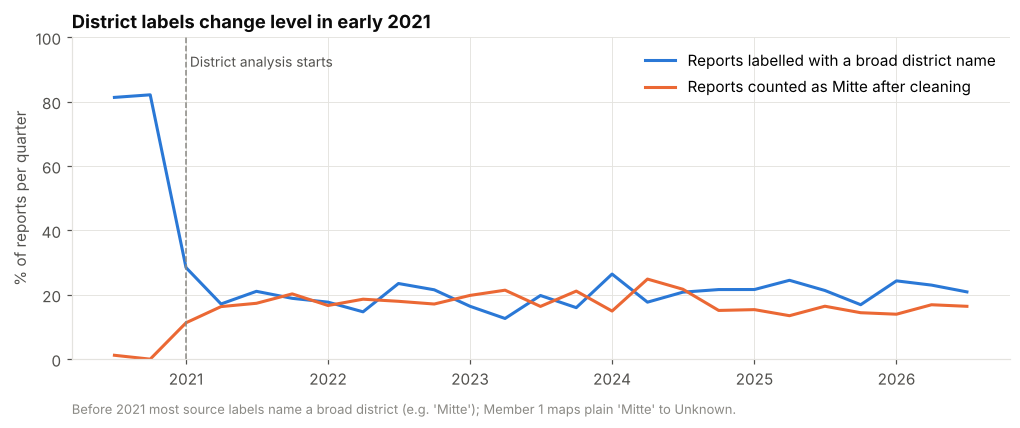

In [13]:
# Figure 2: the labelling change and its effect on Mitte.
fig, ax = plt.subplots(figsize=(11, 3.8))
qx = label_level.index.to_timestamp()
ax.plot(qx, label_level["broad_district_label"] * 100, color=BLUE, lw=2)
ax.plot(qx, label_level["Mitte_after_cleaning"] * 100, color=ORANGE, lw=2)
ax.lines[0].set_label("Reports labelled with a broad district name")
ax.lines[1].set_label("Reports counted as Mitte after cleaning")
ax.legend(frameon=False, loc="upper right")
ax.axvline(DISTRICT_START.to_timestamp(), color=MUTED, ls="--", lw=1)
ax.text(DISTRICT_START.to_timestamp(), 95, " District analysis starts", color=INK2, fontsize=9, va="top")
ax.set(title="District labels change level in early 2021", ylabel="% of reports per quarter", ylim=(0, 100))
ax.text(0, -0.17, "Before 2021 most source labels name a broad district (e.g. 'Mitte'); Member 1 maps plain 'Mitte' to Unknown.",
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
save_figure(fig, "fig2_district_label_change.png")

**Explain your output:**

- **Coverage:** 4 reports exist in July 2019, then nothing until 16 July 2020. The gap (Aug 2019 to Jun 2020) is missing collection, not zero crime. July 2019, July 2020 and September 2026 are partial months.
- **Windows:** citywide analysis uses the 73 complete months from 2020-08 to 2026-08. Partial years are compared as reports per complete month, never as yearly totals.
- **Publication pattern:** never more than 8 reports on one day, and far fewer on Saturdays. The data follows the police press office's publishing rhythm, so counts describe published reports, not all crime.
- **District labels change level:** in 2020 over 80% of reports carry a broad district name such as "Mitte"; from 2021 most carry a neighbourhood name. Because Member 1 maps plain "Mitte" to Unknown, Mitte looks almost empty in 2020 (Figure 2). District-level analysis therefore starts in **2021-01**.
- **Uncertain:** whether the label change also changed which reports were collected. Citywide volumes do not jump at the change, which suggests it did not.

### 3. Calculate monthly district/category counts

Create a month field and use groupby/size. Export monthly_counts.csv. Produce clear time-series plots for selected important categories/districts rather than hundreds of lines on one chart. Check chart totals against the same eligible report cohort.

In [14]:
# monthly_counts.csv: every observed month x district x category, zero-filled within observed months only.
observed_months = [m for m in all_months if observed[m]]
districts = sorted(cohort["district_clean"].unique())
category_list = sorted(cohort["crime_category"].unique())
grid = pd.MultiIndex.from_product([observed_months, districts, category_list],
                                  names=["month", "district_clean", "crime_category"])
monthly_counts = (cohort.groupby(["month", "district_clean", "crime_category"]).size()
                  .reindex(grid, fill_value=0).rename("report_count").reset_index())

def coverage_note(month):
    if month in partial_months:
        days = cohort.loc[cohort["month"].eq(month), "date_posted"]
        return f"partial_month: reports {days.min().date()} to {days.max().date()}"
    if month < DISTRICT_START:
        return "complete_month; broad district labels, Mitte undercounted (use citywide totals only)"
    return "complete_month"

notes = {m: coverage_note(m) for m in observed_months}
monthly_counts["coverage_note"] = monthly_counts["month"].map(notes)
monthly_counts["month"] = monthly_counts["month"].astype(str)
monthly_counts = monthly_counts[schemas["monthly_counts.csv"]]
assert monthly_counts["report_count"].sum() == len(cohort)
assert not monthly_counts.duplicated(["month", "district_clean", "crime_category"]).any()
print("monthly_counts rows:", len(monthly_counts), "| months:", len(observed_months),
      "| districts:", len(districts), "| categories:", len(category_list))
monthly_counts.loc[monthly_counts["report_count"].gt(0)].head()

monthly_counts rows: 1824 | months: 76 | districts: 24 | categories: 1


,month,district_clean,crime_category,report_count,coverage_note
1,2019-07,Blumenthal,All reports (categories pending),3,partial_month: reports 2019-07-14 to 2019-07-17
5,2019-07,Gröpelingen,All reports (categories pending),1,partial_month: reports 2019-07-14 to 2019-07-17
15,2019-07,Schwachhausen,All reports (categories pending),1,partial_month: reports 2019-07-14 to 2019-07-17
18,2019-07,Unknown,All reports (categories pending),5,partial_month: reports 2019-07-14 to 2019-07-17
20,2019-07,Vegesack,All reports (categories pending),1,partial_month: reports 2019-07-14 to 2019-07-17


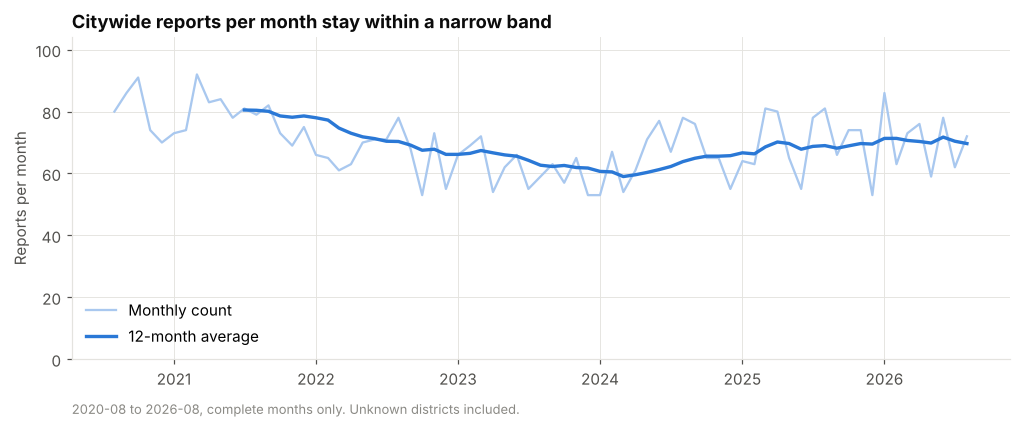

In [15]:
# Figure 3: citywide reports per month with a 12-month rolling average.
city = monthly_total.loc[CITY_START:END_MONTH]
rolling = city.rolling(12, min_periods=12).mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
cx = city.index.to_timestamp()
ax.plot(cx, city.values, color=LIGHT_BLUE, lw=1.5)
ax.plot(cx, rolling.values, color=BLUE, lw=2.2)
ax.lines[0].set_label("Monthly count"); ax.lines[1].set_label("12-month average")
ax.legend(frameon=False, loc="lower left")
ax.set(title="Citywide reports per month stay within a narrow band", ylabel="Reports per month", ylim=(0, city.max() + 12))
ax.text(0, -0.17, f"{CITY_START} to {END_MONTH}, complete months only. Unknown districts included.",
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
save_figure(fig, "fig3_citywide_monthly.png")

In [16]:
# District trends from DISTRICT_START: reports per month by year and a monotonic trend test.
dwin = cohort.loc[cohort["month"].between(DISTRICT_START, END_MONTH)].copy()
dmonths = pd.period_range(DISTRICT_START, END_MONTH, freq="M")
district_monthly = (dwin.groupby(["district_clean", "month"]).size().unstack(fill_value=0)
                    .reindex(columns=dmonths, fill_value=0))

year_cols = {}
for year in sorted(set(dmonths.year)):
    cols = [m for m in dmonths if m.year == year]
    label = str(year) if len(cols) == 12 else f"{year} ({len(cols)} mo)"
    year_cols[label] = district_monthly[cols].mean(axis=1)
district_years = pd.DataFrame(year_cols)

def holm(pvalues):
    order = np.argsort(pvalues); adjusted = np.empty(len(pvalues)); running = 0
    for rank, idx in enumerate(order):
        running = max(running, min(1, (len(pvalues) - rank) * pvalues[idx]))
        adjusted[idx] = running
    return adjusted

trend = []
for district, series in district_monthly.iterrows():
    tau, p = kendalltau(np.arange(len(series)), series.values)
    trend.append({"district_clean": district, "reports": int(series.sum()), "kendall_tau": tau, "p_value": p})
trend = pd.DataFrame(trend)
trend["p_holm"] = holm(trend["p_value"].fillna(1).to_numpy())
trend["direction"] = np.where(trend["p_holm"] < 0.05, np.where(trend["kendall_tau"] > 0, "rising", "falling"), "no clear trend")
district_trends = district_years.round(1).join(trend.set_index("district_clean")[["reports", "kendall_tau", "p_holm", "direction"]])
district_trends = district_trends.sort_values("reports", ascending=False)
display(district_trends.round(3))

,2021,2022,2023,2024,2025,2026 (8 mo),reports,kendall_tau,p_holm,direction
district_clean,,,,,,,,,,
Unknown,11.2,10.2,11.8,12.7,14.4,14.5,838,0.223,0.206,no clear trend
Mitte,12.8,11.7,12.2,12.8,10.4,11.1,807,-0.097,1.000,no clear trend
Neustadt,7.3,4.9,4.1,5.2,5.2,8.4,389,-0.006,1.000,no clear trend
Walle,5.6,5.3,2.3,5.3,4.2,6.2,324,0.028,1.000,no clear trend
Hemelingen,6.4,3.5,3.5,2.7,4.8,2.5,271,-0.240,0.133,no clear trend
Gröpelingen,4.9,3.2,2.2,3.6,4.9,4.6,263,0.049,1.000,no clear trend
Östliche Vorstadt,3.7,2.2,3.1,2.8,3.2,4.0,211,0.081,1.000,no clear trend
Vegesack,2.8,3.7,2.8,2.1,2.5,2.6,186,-0.028,1.000,no clear trend
Huchting,2.4,2.6,2.5,2.5,1.9,1.8,157,-0.123,1.000,no clear trend


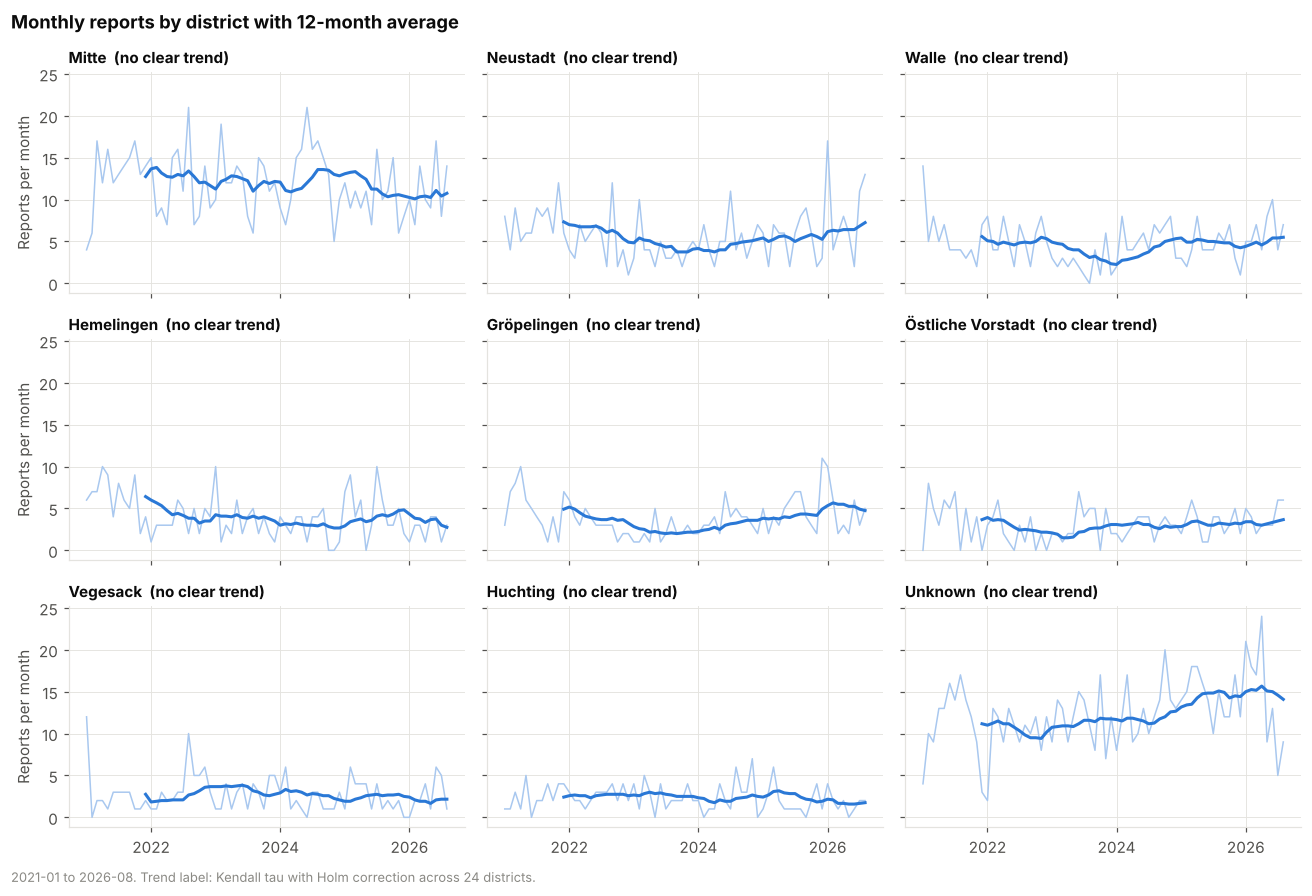

In [17]:
# Figure 4: monthly reports for the eight largest districts and Unknown (same y-scale).
top = district_trends.drop(index="Unknown").head(8).index.tolist() + ["Unknown"]
fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True, sharey=True)
dx = dmonths.to_timestamp()
for ax, district in zip(axes.flat, top):
    series = district_monthly.loc[district]
    ax.plot(dx, series.values, color=LIGHT_BLUE, lw=1)
    ax.plot(dx, series.rolling(12, min_periods=12).mean().values, color=BLUE, lw=2)
    ax.set_title(f"{district}  ({district_trends.loc[district, 'direction']})", fontsize=10)
    ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in axes[:, 0]:
    ax.set_ylabel("Reports per month")
fig.suptitle("Monthly reports by district with 12-month average", x=0.01, ha="left", fontweight="bold", color=INK)
fig.text(0.01, -0.01, f"{DISTRICT_START} to {END_MONTH}. Trend label: Kendall tau with Holm correction across {len(trend)} districts.",
         color=MUTED, fontsize=8.5)
fig.tight_layout()
save_figure(fig, "fig4_district_monthly.png")

In [18]:
# Category trends run only after Member 6 approves categories.
if CATEGORY_MODE:
    cat_monthly = (cohort.loc[cohort["month"].between(CITY_START, END_MONTH)]
                   .groupby(["crime_category", "month"]).size().unstack(fill_value=0)
                   .reindex(columns=pd.period_range(CITY_START, END_MONTH, freq="M"), fill_value=0))
    top_categories = cat_monthly.sum(axis=1).sort_values(ascending=False).head(9).index
    fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True)
    for ax, category in zip(axes.flat, top_categories):
        series = cat_monthly.loc[category]
        ax.plot(series.index.to_timestamp(), series.values, color=LIGHT_BLUE, lw=1)
        ax.plot(series.index.to_timestamp(), series.rolling(12, min_periods=12).mean().values, color=BLUE, lw=2)
        ax.set_title(category, fontsize=10)
    fig.suptitle("Monthly reports by approved crime category", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save_figure(fig, "fig4b_category_monthly.png")
else:
    print("Category trends skipped:", category_check)

Category trends skipped: report_categories.csv or selected_model.json not published yet


**Explain your output:**

- **Citywide:** volume stays in a narrow band of 53 to 92 reports per month. The 12-month average falls from about 80 (2021) to about 60 (early 2024) and recovers to about 70 by 2026 (Figure 3).
- **Districts:** Mitte has the most reports (about 11 to 13 per month), then Neustadt, Walle, Hemelingen and Gröpelingen. After correcting for testing 24 districts, **no district shows a significant rising or falling trend**. Neustadt is higher in 2026 (8.4 per month) than in 2022 to 2025 (4 to 5), but 8 months is too short to call a trend.
- **Unknown districts grow** from about 11 to 15 reports per month (not significant after correction). If this continues, named districts will look lower in later years for labelling reasons.
- **Uncertain:** trends by crime type are the main part of Question 2 and need the approved categories.

### 4. Examine seasonal patterns

Compare calendar months across comparable years/months. A simple average per observed eligible month is a starting point; document which months/years enter each denominator. Distinguish a repeated seasonal pattern from one isolated spike or a change in source coverage. Export seasonal_summary.csv.

In [19]:
# Seasonality uses complete calendar years only, so every calendar month has the same number of observations.
complete_years = sorted(set(m.year for m in complete_months))
complete_years = [y for y in complete_years if all(pd.Period(f"{y}-{mm:02d}", "M") in complete_months for mm in range(1, 13))]
season_base = cohort.loc[cohort["date_posted"].dt.year.isin(complete_years)].copy()
season_base["calendar_month"] = season_base["date_posted"].dt.month
print("Complete years used for seasonality:", complete_years)

def seasonal_table(frame, label):
    counts = frame.groupby("calendar_month").size().reindex(range(1, 13), fill_value=0)
    observed_n = frame.groupby("calendar_month")["month"].nunique().reindex(range(1, 13), fill_value=0)
    observed_n[:] = len(complete_years)
    return pd.DataFrame({"calendar_month": range(1, 13), "crime_category": label,
                         "report_count": counts.values, "observed_months": observed_n.values,
                         "mean_reports_per_observed_month": (counts / len(complete_years)).round(2).values})

parts = [seasonal_table(season_base, ALL_LABEL if CATEGORY_MODE else PENDING_LABEL)]
if CATEGORY_MODE:
    parts += [seasonal_table(group, category) for category, group in season_base.groupby("crime_category")]
seasonal_summary = pd.concat(parts, ignore_index=True)[schemas["seasonal_summary.csv"]]
assert seasonal_summary.loc[seasonal_summary["crime_category"].isin([ALL_LABEL, PENDING_LABEL]), "report_count"].sum() == len(season_base)

# Per-day rates remove the effect of shorter months such as February.
yearly = season_base.groupby([season_base["date_posted"].dt.year, "calendar_month"]).size().unstack()
days = pd.DataFrame({m: [pd.Period(f"{y}-{m:02d}", "M").days_in_month for y in yearly.index] for m in range(1, 13)}, index=yearly.index)
per_day = yearly / days
stat, p_kw = kruskal(*[per_day[m].values for m in range(1, 13)])
season_view = pd.DataFrame({"mean_per_month": yearly.mean().round(1), "mean_per_day": per_day.mean().round(2),
                            "min_year": yearly.min(), "max_year": yearly.max()})
season_view.index = [pd.Timestamp(2000, m, 1).strftime("%b") for m in season_view.index]
display(season_view.T)
print(f"Kruskal-Wallis across calendar months (reports per day, {len(complete_years)} years each): H = {stat:.1f}, p = {p_kw:.3f}")

Complete years used for seasonality: [2021, 2022, 2023, 2024, 2025]


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
mean_per_month,64.40,67.6,72.00,68.20,70.40,69.40,70.40,75.00,71.00,64.40,69.20,58.20
mean_per_day,2.08,2.4,2.32,2.27,2.27,2.31,2.27,2.42,2.37,2.08,2.31,1.88
min_year,53.00,63.0,54.00,54.00,62.00,55.00,55.00,59.00,63.00,53.00,65.00,53.00
max_year,73.00,74.0,92.00,83.00,84.00,78.00,81.00,81.00,82.00,74.00,74.00,75.00


Kruskal-Wallis across calendar months (reports per day, 5 years each): H = 13.1, p = 0.284


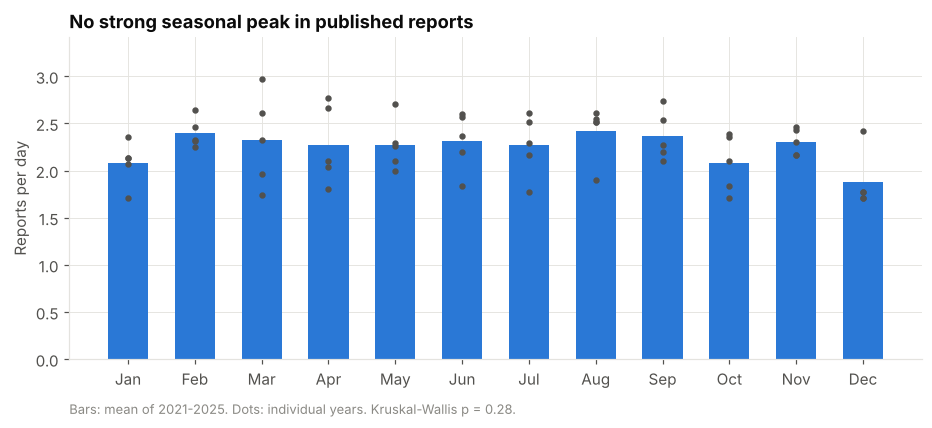

In [20]:
# Figure 5: average reports per day by calendar month, with each year's value as a dot.
fig, ax = plt.subplots(figsize=(10, 3.8))
month_names = [pd.Timestamp(2000, m, 1).strftime("%b") for m in range(1, 13)]
ax.bar(month_names, per_day.mean().values, color=BLUE, width=0.6)
for year in per_day.index:
    ax.scatter(month_names, per_day.loc[year].values, color=INK2, s=10, zorder=3)
ax.set(title="No strong seasonal peak in published reports", ylabel="Reports per day",
       ylim=(0, per_day.values.max() * 1.15))
ax.text(0, -0.17, f"Bars: mean of {complete_years[0]}-{complete_years[-1]}. Dots: individual years. "
        f"Kruskal-Wallis p = {p_kw:.2f}.", transform=ax.transAxes, color=MUTED, fontsize=8.5)
save_figure(fig, "fig5_seasonality.png")

In [21]:
# Holiday weeks: weeks containing a public holiday in Bremen or New Year's Eve.
def bremen_holidays(year):
    e = pd.Timestamp(easter(year))
    fixed = [f"{year}-01-01", f"{year}-05-01", f"{year}-10-03", f"{year}-10-31", f"{year}-12-24",
             f"{year}-12-25", f"{year}-12-26", f"{year}-12-31"]
    return [pd.Timestamp(d) for d in fixed] + [e - pd.Timedelta(days=2), e + pd.Timedelta(days=1),
                                               e + pd.Timedelta(days=39), e + pd.Timedelta(days=50)]

holiday_days = {d for y in range(2020, 2027) for d in bremen_holidays(y)}
week_start = cohort["date_posted"] - pd.to_timedelta(cohort["date_posted"].dt.dayofweek, unit="D")
weekly = cohort.assign(week=week_start).groupby("week").size()
weeks = pd.date_range(CITY_START.to_timestamp() + pd.offsets.Week(weekday=0),
                      END_MONTH.to_timestamp(how="end").normalize() - pd.Timedelta(days=6), freq="W-MON")
weekly = weekly.reindex(weeks, fill_value=0)
is_holiday = pd.Series([any(w + pd.Timedelta(days=i) in holiday_days for i in range(7)) for w in weeks], index=weeks)
holiday_compare = pd.DataFrame({"weeks": [is_holiday.sum(), (~is_holiday).sum()],
                                "mean_reports_per_week": [weekly[is_holiday].mean(), weekly[~is_holiday].mean()]},
                               index=["holiday week", "other week"]).round(2)
u, p_holiday = mannwhitneyu(weekly[is_holiday], weekly[~is_holiday])
display(holiday_compare)
print(f"Mann-Whitney U test, holiday vs other weeks: p = {p_holiday:.3f}")

,weeks,mean_reports_per_week
holiday week,55,14.80
other week,262,16.24


Mann-Whitney U test, holiday vs other weeks: p = 0.014


**Explain your output:**

- **No clear seasonal peak:** reports per day vary only between 1.9 (December) and 2.4 (February, August), and the difference across calendar months is not significant (Kruskal-Wallis p = 0.28, 5 complete years per month).
- **December has the lowest average** (1.9 reports per day) and is among the three lowest months in 4 of the 5 years. This fits a publishing pattern (holidays, fewer press releases) better than a drop in crime.
- **Holiday weeks have fewer published reports:** 14.8 per week against 16.2 in other weeks (p = 0.014). So holidays do not create spikes in the overall count.
- **Uncertain:** specific crime types may still be seasonal (e.g. burglary in winter, fireworks around New Year's Eve, football around the stadium). This test needs the approved categories.

### 5. Define and investigate unusual increases

Choose a transparent rule for candidate peaks: for example a rolling baseline with a documented threshold. Record the time window, count, baseline and rule in anomalies.csv. Be cautious with sparse categories and many district comparisons. Read the underlying reports to investigate holidays, linked events or reporting changes; keep unverified explanations as hypotheses.

In [22]:
# Spike rule: compare each period with the average of the previous periods (rolling baseline).
# A period is a candidate when count >= MIN_COUNT, count >= MULTIPLE x baseline and Poisson p < ALPHA.
# Because hundreds of periods are tested, "strong" also requires p < 0.05 / number of tests (Bonferroni).
ALPHA = 0.001

def detect_spikes(table, freq, baseline_periods, min_periods, min_count, multiple, category_label, run_name):
    rows, n_tests = [], 0
    for key, series in table.iterrows():
        baseline = series.shift(1).rolling(baseline_periods, min_periods=min_periods).mean()
        tested = baseline.notna()
        n_tests += int(tested.sum())
        pvalue = pd.Series(poisson.sf(series.values - 1, baseline.fillna(0).values), index=series.index)
        flag = tested & series.ge(min_count) & series.ge(multiple * baseline) & pvalue.lt(ALPHA)
        district, category = key if isinstance(key, tuple) else (key, category_label)
        for period in series.index[flag.values]:
            start = period.start_time.normalize(); end = period.end_time.normalize()
            rows.append({"run": run_name, "district_clean": district, "crime_category": category,
                         "window_start": start, "window_end": end, "report_count": int(series[period]),
                         "baseline_count": round(float(baseline[period]), 2), "p_value": float(pvalue[period])})
    found = pd.DataFrame(rows, columns=["run", "district_clean", "crime_category", "window_start", "window_end",
                                        "report_count", "baseline_count", "p_value"])
    found["tier"] = np.where(found["p_value"] < 0.05 / max(n_tests, 1), "strong", "screening")
    found["method"] = (f"{run_name}: {freq} counts vs mean of previous {baseline_periods} {freq}s "
                       f"(min {min_periods}); flag if count>={min_count}, >={multiple}x baseline, Poisson p<{ALPHA}; "
                       f"{n_tests} tests, Bonferroni p<{0.05 / max(n_tests, 1):.1e}")
    return found, {"run": run_name, "tests": n_tests, "candidates": len(found),
                   "expected_by_chance": round(n_tests * ALPHA, 1), "strong": int(found["tier"].eq("strong").sum())}

dcohort = cohort.loc[cohort["month"].between(DISTRICT_START, END_MONTH)].copy()
dcohort["week"] = dcohort["date_posted"].dt.to_period("W-SUN")
week_index = pd.period_range(dcohort["week"].min(), dcohort["week"].max(), freq="W-SUN")
week_index = week_index[(week_index.start_time >= DISTRICT_START.start_time) & (week_index.end_time <= END_MONTH.end_time)]
dcohort = dcohort.loc[dcohort["week"].isin(week_index)]

runs = []
month_table = (cohort.loc[cohort["month"].between(DISTRICT_START, END_MONTH)]
               .groupby(["district_clean", "month"]).size().unstack(fill_value=0).reindex(columns=dmonths, fill_value=0))
runs.append(detect_spikes(month_table.drop(index="Unknown", errors="ignore"), "month", 12, 6, 5, 2, ALL_LABEL, "district-month"))
week_table = dcohort.groupby(["district_clean", "week"]).size().unstack(fill_value=0).reindex(columns=week_index, fill_value=0)
runs.append(detect_spikes(week_table.drop(index="Unknown", errors="ignore"), "week", 26, 13, 4, 3, ALL_LABEL, "district-week"))
if CATEGORY_MODE:
    cw = dcohort.groupby(["crime_category", "week"]).size().unstack(fill_value=0).reindex(columns=week_index, fill_value=0)
    cw.index = pd.MultiIndex.from_tuples([("Citywide", c) for c in cw.index])
    runs.append(detect_spikes(cw, "week", 26, 13, 4, 2, None, "category-week (citywide)"))
    dcm = (cohort.loc[cohort["month"].between(DISTRICT_START, END_MONTH) & cohort["district_clean"].ne("Unknown")]
           .groupby(["district_clean", "crime_category", "month"]).size().unstack(fill_value=0).reindex(columns=dmonths, fill_value=0))
    runs.append(detect_spikes(dcm, "month", 12, 6, 4, 2, None, "district-category-month"))

candidates = pd.concat([r[0] for r in runs], ignore_index=True).sort_values("p_value").reset_index(drop=True)
display(pd.DataFrame([r[1] for r in runs]))
display(candidates.drop(columns="method").assign(p_value=lambda t: t["p_value"].map("{:.1e}".format),
                                                 window_start=lambda t: t["window_start"].dt.date,
                                                 window_end=lambda t: t["window_end"].dt.date))

,run,tests,candidates,expected_by_chance,strong
0,district-month,1426,4,1.4,0
1,district-week,6486,6,6.5,0


,run,district_clean,crime_category,window_start,window_end,report_count,baseline_count,p_value,tier
0,district-month,Neustadt,All reports,2026-01-01,2026-01-31,17,5.25,3.6e-05,screening
1,district-month,Vegesack,All reports,2022-08-01,2022-08-31,10,2.08,6.5e-05,screening
2,district-week,Hemelingen,All reports,2023-01-23,2023-01-29,6,0.88,3.1e-04,screening
3,district-month,Woltmershausen,All reports,2025-04-01,2025-04-30,5,0.58,3.5e-04,screening
4,district-week,Findorff,All reports,2023-11-13,2023-11-19,4,0.35,4.5e-04,screening
5,district-month,Burglesum,All reports,2024-01-01,2024-01-31,8,1.75,4.7e-04,screening
6,district-week,Vahr,All reports,2026-06-01,2026-06-07,4,0.38,6.7e-04,screening
7,district-week,Walle,All reports,2026-03-02,2026-03-08,6,1.04,7.2e-04,screening
8,district-week,Hemelingen,All reports,2025-02-24,2025-03-02,5,0.73,9.5e-04,screening
9,district-week,Vegesack,All reports,2026-06-22,2026-06-28,4,0.42,9.5e-04,screening


In [23]:
# Read the reports behind each candidate (titles only; full text stays in the source).
def candidate_reports(row):
    mask = (cohort["date_posted"].between(row.window_start, row.window_end) & cohort["district_clean"].eq(row.district_clean)
            if row.district_clean != "Citywide" else cohort["date_posted"].between(row.window_start, row.window_end))
    if row.crime_category not in (ALL_LABEL, PENDING_LABEL):
        mask &= cohort["crime_category"].eq(row.crime_category)
    return cohort.loc[mask].sort_values("date_posted")

for row in candidates.itertuples():
    found = candidate_reports(row)
    print(f"\n{row.district_clean} | {row.crime_category} | {row.window_start.date()} to {row.window_end.date()} "
          f"| {row.report_count} reports vs baseline {row.baseline_count} | {row.tier}")
    print(found[["report_id", "date_posted", "district", "title_en"]].head(12)
          .assign(date_posted=lambda t: t["date_posted"].dt.date).to_string(index=False, max_colwidth=70))


Neustadt | All reports | 2026-01-01 to 2026-01-31 | 17 reports vs baseline 5.25 | screening
report_id date_posted      district                                                      title_en
 BR000574  2026-01-01 Alte Neustadt                                  Police operation in Neustadt
 BR000562  2026-01-06 Alte Neustadt               Burglar found sleeping after snack bar break-in
 BR000563  2026-01-06 Alte Neustadt                Perpetrator apprehended after vehicle break-in
 BR000555  2026-01-08 Alte Neustadt                 After shots in Neustadt: 27-year-old arrested
 BR000554  2026-01-09      Neustadt                       Unknowns attack 22-year-old in Neustadt
 BR000551  2026-01-11     Buntentor                                           Burglar apprehended
 BR000548  2026-01-12      Neustadt                        Drug trafficking uncovered in Neustadt
 BR000543  2026-01-14      Neustadt                                   Building smeared with paint
 BR000541  2026-01-15    

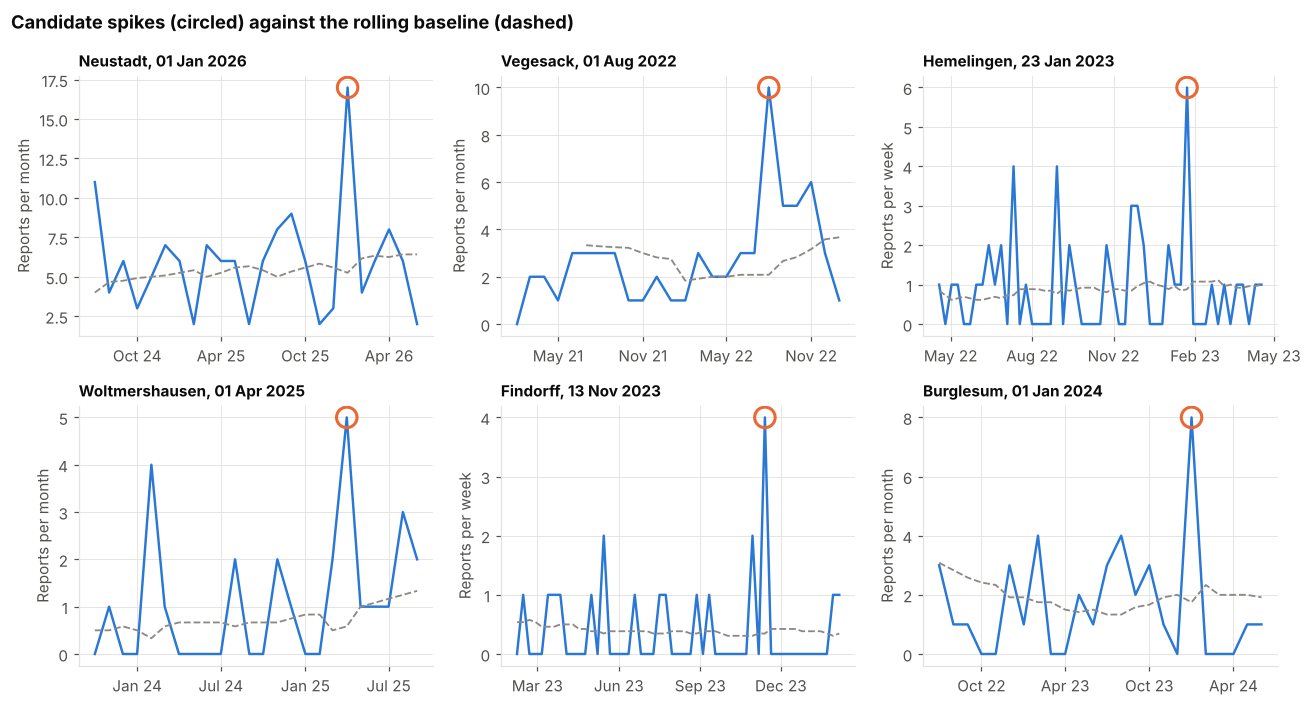

In [24]:
# Figure 6: each candidate in its own series, with the flagged period circled.
shown = candidates.loc[candidates["run"].isin(["district-month", "district-week"])].head(6)
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, row in zip(axes.flat, shown.itertuples()):
    table = month_table if row.run == "district-month" else week_table
    series = table.loc[row.district_clean]
    period = (pd.Period(row.window_start, "M") if row.run == "district-month" else pd.Period(row.window_start, "W-SUN"))
    span = 18 if row.run == "district-month" else 40
    pos = series.index.get_loc(period)
    part = series.iloc[max(0, pos - span): pos + span // 3]
    baseline = (series.shift(1).rolling(12, min_periods=6) if row.run == "district-month"
                else series.shift(1).rolling(26, min_periods=13)).mean().loc[part.index]
    px = part.index.to_timestamp()
    ax.plot(px, part.values, color=BLUE, lw=1.6)
    ax.plot(px, baseline.values, color=MUTED, lw=1.2, ls="--")
    ax.scatter([period.to_timestamp()], [row.report_count], s=180, facecolors="none", edgecolors=ORANGE, linewidths=2, zorder=4)
    ax.set_title(f"{row.district_clean}, {row.window_start:%d %b %Y}", fontsize=10)
    ax.set_ylabel(f"Reports per {row.run.split('-')[1]}")
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6 if row.run == "district-month" else 3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
for ax in axes.flat[len(shown):]:
    ax.set_visible(False)
fig.suptitle("Candidate spikes (circled) against the rolling baseline (dashed)", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
save_figure(fig, "fig6_spike_candidates.png")

**Explain your output:**

- **Rule:** a district-month or district-week is a candidate when it has at least 5 (weekly: 4) reports, at least twice (weekly: three times) its rolling baseline, and a Poisson probability below 0.001. Unknown is excluded because it is not a place.
- **Result:** 10 candidates from about 7,900 tests, where about 8 would be expected by chance alone. **None passes the stricter Bonferroni threshold.** Statistically, district spikes in all reports are not more frequent than random variation.
- **Reading the reports still explains most candidates** (next section). The largest ones come from a single incident published several times or from unrelated reports in the same week.
- **Uncertain:** spikes within one crime type (e.g. a burglary series in one district) can be hidden in all-report counts. The category-week and district-category-month runs add these once categories are approved.

### 6. Write evidence-based interpretations

For each important anomaly, include traceable report/source evidence where possible. A holiday and a peak occurring together do not prove causation. Separate observed change, possible explanation and evidence strength. If no anomaly meets the rule, submit the correct empty anomalies CSV and explain the result rather than manufacturing a finding.

In [25]:
# Reviewed explanations from reading the reports in Section 5. Keys: (district, category, window start).
# Unreviewed candidates (e.g. new ones once categories arrive) stay marked "not_reviewed".
REVIEWED = {
    ("Neustadt", ALL_LABEL, "2026-01-01"): (
        "Mixed offences across several Neustadt neighbourhoods (four burglaries, a shooting, an assault, drugs, graffiti, an assembly). "
        "No single event; the month continues a higher Neustadt level from late 2025 (8.4 reports/month in 2026 vs 5.2 in 2025).",
        "reports_read_no_common_driver", ["BR000555", "BR000562", "BR000548"]),
    ("Vegesack", ALL_LABEL, "2022-08-01"): (
        "Half of the 10 reports are robberies or robbery arrests (gas station, amusement arcade, specialty store, handbag). "
        "Possible short robbery series in Vegesack; the reports do not state that the cases are linked.",
        "reports_read_possible_series", ["BR003267", "BR003220", "BR003203"]),
    ("Hemelingen", ALL_LABEL, "2023-01-23"): (
        "Cluster of accident reports (pedestrian critically injured then reported dead, A1 crash, industrial accident). "
        "The pedestrian case appears twice, so the week counts one incident as two reports.",
        "reports_read_follow_up_reports", ["BR002889", "BR002888", "BR002894"]),
    ("Woltmershausen", ALL_LABEL, "2025-04-01"): (
        "Five unrelated incidents (car break-in, shooting, taser use, traffic accident, kiosk robbery). "
        "Small-number effect in a district that usually has about one report per month.",
        "reports_read_no_common_driver", ["BR001179", "BR001149", "BR001186"]),
    ("Findorff", ALL_LABEL, "2023-11-13"): (
        "Burning street barricades at Bürgerweide followed by an investigation of a claim of responsibility (linked reports), "
        "plus two unrelated burglary arrests on the same day.",
        "reports_read_follow_up_reports", ["BR002290", "BR002287"]),
    ("Burglesum", ALL_LABEL, "2024-01-01"): (
        "Two releases about the same police operation in Burg-Grambke, a farmers' protest blocking traffic during the January 2024 protest wave, "
        "and several burglary or theft arrests. Partly follow-up reporting; no single crime driver.",
        "reports_read_follow_up_reports", ["BR002172", "BR002170", "BR002187"]),
    ("Vahr", ALL_LABEL, "2026-06-01"): (
        "One fatal garbage-truck accident reported twice (initial report and death), plus a fire and a robbery of a 91-year-old woman.",
        "reports_read_follow_up_reports", ["BR000210", "BR000209", "BR000200"]),
    ("Walle", ALL_LABEL, "2026-03-02"): (
        "Three releases on 2 March about Überseestadt (shots fired, arson with a confession letter, traffic fines) plus burglary arrests. "
        "Separate incidents published together; no single driver.",
        "reports_read_no_common_driver", ["BR000420", "BR000423", "BR000422"]),
    ("Hemelingen", ALL_LABEL, "2025-02-24"): (
        "Unrelated reports (pedestrian hit, car burglar arrested, truck overtaking checks, arrest warrant). No common driver.",
        "reports_read_no_common_driver", ["BR001282", "BR001290", "BR001291"]),
    ("Vegesack", ALL_LABEL, "2026-06-22"): (
        "All four reports concern one double homicide and the following manhunt and arrest. One incident, four releases.",
        "reports_read_follow_up_reports", ["BR000151", "BR000150", "BR000145"]),
}


def explain(row):
    key = (row.district_clean, ALL_LABEL if row.crime_category == PENDING_LABEL else row.crime_category, str(row.window_start.date()))
    explanation, status, ids = REVIEWED.get(key, ("Not yet investigated: read the listed reports.", "not_reviewed", []))
    found = candidate_reports(row)
    urls = found.loc[found["report_id"].isin(ids), "url"].tolist() if ids else found["url"].head(3).tolist()
    return pd.Series({"possible_explanation": explanation, "evidence_status": status, "evidence_url": "; ".join(urls)})

anomalies = candidates.join(candidates.apply(explain, axis=1))
anomalies["window_start"] = anomalies["window_start"].dt.strftime("%Y-%m-%d")
anomalies["window_end"] = anomalies["window_end"].dt.strftime("%Y-%m-%d")
anomalies["method"] = anomalies["method"] + "; tier=" + anomalies["tier"] + f"; p=" + anomalies["p_value"].map("{:.1e}".format)
anomalies = anomalies[schemas["anomalies.csv"]]
display(anomalies[["district_clean", "window_start", "report_count", "baseline_count", "evidence_status", "possible_explanation"]])

,district_clean,window_start,report_count,baseline_count,evidence_status,possible_explanation
0,Neustadt,2026-01-01,17,5.25,reports_read_no_common_driver,Mixed offences across several Neustadt neighbo...
1,Vegesack,2022-08-01,10,2.08,reports_read_possible_series,Half of the 10 reports are robberies or robber...
2,Hemelingen,2023-01-23,6,0.88,reports_read_follow_up_reports,Cluster of accident reports (pedestrian critic...
3,Woltmershausen,2025-04-01,5,0.58,reports_read_no_common_driver,"Five unrelated incidents (car break-in, shooti..."
4,Findorff,2023-11-13,4,0.35,reports_read_follow_up_reports,Burning street barricades at Bürgerweide follo...
5,Burglesum,2024-01-01,8,1.75,reports_read_follow_up_reports,Two releases about the same police operation i...
6,Vahr,2026-06-01,4,0.38,reports_read_follow_up_reports,One fatal garbage-truck accident reported twic...
7,Walle,2026-03-02,6,1.04,reports_read_no_common_driver,Three releases on 2 March about Überseestadt (...
8,Hemelingen,2025-02-24,5,0.73,reports_read_no_common_driver,"Unrelated reports (pedestrian hit, car burglar..."
9,Vegesack,2026-06-22,4,0.42,reports_read_follow_up_reports,All four reports concern one double homicide a...


**Explain your output:**

| Pattern found in the reports | Candidates |
|---|---|
| One incident published several times (follow-up releases) | Vegesack Jun 2026 (double homicide, 4 releases), Vahr Jun 2026 (fatal accident, 2 releases), Hemelingen Jan 2023, Findorff Nov 2023, Burglesum Jan 2024 |
| Possible short crime series | Vegesack Aug 2022 (5 robbery-related reports in one month) |
| Unrelated reports in the same period | Neustadt Jan 2026, Woltmershausen Apr 2025, Walle Mar 2026, Hemelingen Feb 2025 |

- **Answer to "what drives these anomalies" (so far):** mainly how the police publish (follow-up releases on one case), plus one possible robbery series. No spike lines up with a public holiday; one coincides with the national farmers' protests (January 2024).
- **Evidence strength:** each explanation comes from reading the report titles and texts behind the spike and is recorded with source URLs in `anomalies.csv`. They are hypotheses, not proven causes.

### 7. Export trends, seasonal tables and anomalies

Submit the three tables, metadata and handover. Save legible monthly/seasonal figures and focused anomaly plots. Include exact periods, frequency, counting unit, exclusions, baseline definition and limitations. All totals should reconcile with approved included reports.

In [26]:
# Export the three contract tables after validating their schemas.
for name, table in [("monthly_counts.csv", monthly_counts), ("seasonal_summary.csv", seasonal_summary),
                    ("anomalies.csv", anomalies)]:
    assert table.columns.tolist() == schemas[name], name
    assert table.columns.tolist() == pd.read_csv(project_folder / "templates/member_05" / name).columns.tolist()
    table.to_csv(output_folder / name, index=False, encoding="utf-8")
    stored = pd.read_csv(output_folder / name, dtype=str, keep_default_na=False)
    assert len(stored) == len(table)
assert pd.read_csv(output_folder / "monthly_counts.csv")["report_count"].sum() == len(cohort)
print({name: len(pd.read_csv(output_folder / name)) for name in ["monthly_counts.csv", "seasonal_summary.csv", "anomalies.csv"]})

{'monthly_counts.csv': 1824, 'seasonal_summary.csv': 12, 'anomalies.csv': 10}


In [27]:
# run_metadata.json from the shared template; versions only for packages this notebook uses.
def package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"

metadata = json.loads((project_folder / "templates/member_05/run_metadata.json").read_text(encoding="utf-8"))
metadata.update({
    "author": "Ghofran Mahmoud", "reviewer": "",
    "status": "in_progress_categories_approved" if CATEGORY_MODE else "in_progress_categories_pending",
    "source_sha256": manifest["raw_sha256"], "base_sha256": manifest["base_sha256"],
    "prepared_sha256": prepared_sha256, "report_categories_sha256": report_categories_sha256,
    "run_date": datetime.now(timezone.utc).isoformat(), "python_version": platform.python_version(),
    "package_versions": {name: package_version(name) for name in ["pandas", "numpy", "pyarrow", "scipy", "matplotlib"]},
    "methods": ["Coverage audit and partial-month flags", "Monthly counts zero-filled within observed months",
                "Kendall tau district trends with Holm correction", "Seasonality over complete years (Kruskal-Wallis on reports per day)",
                "Holiday-week comparison (Mann-Whitney)", "Rolling-baseline Poisson spike rule with Bonferroni tier",
                "Manual reading of reports behind each candidate"],
    "parameters": {"citywide_window": [str(CITY_START), str(END_MONTH)], "district_window": [str(DISTRICT_START), str(END_MONTH)],
                   "seasonality_years": complete_years, "alpha": ALPHA, "category_mode": CATEGORY_MODE,
                   "category_check": category_check, "selected_model_id": selected_model_id,
                   "spike_runs": [r[1] for r in runs]},
    "counts": {"base_reports": len(labeled), "included_reports": len(cohort), "excluded_reports": int((~labeled["include_in_analysis"]).sum()),
               "monthly_counts_rows": len(monthly_counts), "seasonal_summary_rows": len(seasonal_summary),
               "anomaly_rows": len(anomalies), "reviewed_anomalies": int(anomalies["evidence_status"].ne("not_reviewed").sum())},
    "notes": ["Counts are published police reports by publication date, not incidents or crime rates.",
              f"No reports between {gap_months.min()} and {gap_months.max()}; partial months flagged in coverage_note.",
              f"District analysis starts {DISTRICT_START}: earlier source labels are broad districts and plain 'Mitte' maps to Unknown.",
              "Category-level results require Member 6 approval; rerun this notebook when report_categories.csv is approved."],
    "figures": figure_files,
    "output_sha256": {name: sha256(output_folder / name) for name in ["monthly_counts.csv", "seasonal_summary.csv", "anomalies.csv"]},
})
assert set(json.loads((project_folder / "templates/member_05/run_metadata.json").read_text()).keys()) <= set(metadata)
(output_folder / "run_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("run_metadata.json written; status:", metadata["status"])

run_metadata.json written; status: in_progress_categories_pending


In [28]:
# handover.md filled from the template headings.
HANDOVER_BODY = {
"What I completed": """- Sections 1 to 7 of the Role 5 notebook on all 5,124 included reports, by district.
- Coverage audit, monthly counts, district trend tests, seasonality, holiday-week comparison and a spike rule with manual reading of every candidate.
- Category-level trends and spikes are coded and switch on automatically once Member 6 publishes approved categories.""",
"Input files and inclusion rules": """- outputs/member_01/reports_prepared.parquet (SHA-256 checked); include_in_analysis = True only (5,124 reports).
- Counting unit: published reports by date_posted (publication date, not incident date).
- Citywide window: 2020-08 to 2026-08 (complete months). District window: 2021-01 to 2026-08 (district labels change level before 2021).
- No reports exist between 2019-08 and 2020-06; this gap is not treated as zero crime.""",
"Output files and row counts": f"""- monthly_counts.csv: {len(monthly_counts)} rows (observed months x districts x categories, zero-filled within observed months).
- seasonal_summary.csv: {len(seasonal_summary)} rows (calendar month x category, complete years {complete_years[0]} to {complete_years[-1]}).
- anomalies.csv: {len(anomalies)} candidate spikes, each with evidence URLs and a reviewed explanation.
- Figures: {', '.join(figure_files)} in figures/member_05.""",
"Methods and parameter choices": """- Trends: reports per month by year; Kendall tau on monthly counts per district, Holm correction across districts.
- Seasonality: reports per day by calendar month over complete years; Kruskal-Wallis across months.
- Holidays: weeks containing a Bremen public holiday, 24 Dec or 31 Dec vs other weeks (Mann-Whitney).
- Spikes: count vs mean of previous 12 months (district-month) or 26 weeks (district-week); flag if count >= 5 (4 for weeks), >= 2x (3x) baseline and Poisson p < 0.001. "Strong" also needs p < 0.05 / number of tests.""",
"Findings supported by saved outputs": """- Q2 (trends and seasonality): citywide volume is stable at about 60 to 80 reports per month; no district shows a significant monotonic trend after correction; no significant seasonal peak (Kruskal-Wallis p = 0.28), with December lowest per day.
- Q3 (short-term spikes): 10 candidate district spikes against about 8 expected by chance; none pass the Bonferroni threshold. Reading the reports shows the larger ones are often one incident published several times (Vegesack June 2026, Vahr June 2026) or unrelated reports in the same week. Holiday weeks have fewer published reports, not more.""",
"Validation and reviewer comments": """- Schemas match artifact_contracts.json; monthly totals reconcile to 5,124 included reports; files read back after export.
- Reviewer: not assigned yet.""",
"Limitations and unresolved questions": """- Category-level answers (which crime types rise or spike) need Member 6's approved report_categories.csv; rerun this notebook when it is published.
- The dataset looks like a sample of press releases (max 8 per day, flat monthly volume), so trends describe publication, not crime levels.
- Unknown district reports rise from about 11 to 15 per month; district counts may understate later years.
- Recommendation for Member 1: map plain "Mitte" labels to Mitte; 65 of them fall before 2021 and empty Mitte in 2020.""",
"Where these results belong in the main notebook": """- Section 7 (Time patterns, seasonality and investigated anomalies): import the three CSVs and figures fig1 to fig6.
- Answers Questions 2 and 3; Question 3 "drivers" come from the possible_explanation and evidence_url columns.""",
}

template = (project_folder / "templates/member_05/handover.md").read_text(encoding="utf-8")
handover = template.replace("Status: NOT STARTED — this is a template, not a submitted result.",
                            "Status: IN PROGRESS. All-report results complete; category-level results pending Member 6."
                            if not CATEGORY_MODE else "Status: READY FOR REVIEW. Approved categories used.")
for field, value in [("Name:", "Name: Ghofran Mahmoud"), ("Reviewer:", "Reviewer: not assigned yet"),
                     ("Source/base SHA-256:", f"Source/base SHA-256: {manifest['raw_sha256']} / {manifest['base_sha256']}"),
                     ("Prepared dataset SHA-256:", f"Prepared dataset SHA-256: {prepared_sha256}"),
                     ("Final categories SHA-256 (if used):", f"Final categories SHA-256 (if used): {report_categories_sha256 or 'not used (pending)'}"),
                     ("Python/package versions:", f"Python/package versions: {platform.python_version()}; see run_metadata.json")]:
    handover = handover.replace(field + "\n", value + "\n", 1)
for heading, body in HANDOVER_BODY.items():
    handover = handover.replace("## " + heading + "\n", "## " + heading + "\n\n" + body.strip() + "\n", 1)
(output_folder / "handover.md").write_text(handover, encoding="utf-8")
required = contracts["roles"]["member_05"]["required_files"]
assert all((output_folder / name).exists() and (output_folder / name).stat().st_size > 0 for name in required)
print("All required files present:", required)
print("Figures:", figure_files)

All required files present: ['monthly_counts.csv', 'seasonal_summary.csv', 'anomalies.csv', 'run_metadata.json', 'handover.md']
Figures: ['fig1_monthly_coverage.png', 'fig2_district_label_change.png', 'fig3_citywide_monthly.png', 'fig4_district_monthly.png', 'fig5_seasonality.png', 'fig6_spike_candidates.png']


**Explain your output:**

- The three contract tables, `run_metadata.json` and `handover.md` are written to `outputs/member_05`, and six figures to `figures/member_05`.
- Totals reconcile with the 5,124 included reports, and schemas match `artifact_contracts.json`.
- Status stays **in progress** until Member 6 publishes approved categories; then rerun top to bottom, check the new category candidates in Sections 5 and 6, and update the interpretations.

## What you must submit to the main workstation

Submit this completed notebook with saved outputs, your files in outputs/member_05, and figures in figures/member_05. Run the notebook top-to-bottom before submission. Do not submit empty templates as results.

- **monthly_counts.csv** = columns: `month`, `district_clean`, `crime_category`, `report_count`, `coverage_note`.
- **seasonal_summary.csv** = columns: `calendar_month`, `crime_category`, `report_count`, `observed_months`, `mean_reports_per_observed_month`.
- **anomalies.csv** = columns: `district_clean`, `crime_category`, `window_start`, `window_end`, `report_count`, `baseline_count`, `method`, `possible_explanation`, `evidence_url`, `evidence_status`.
- **run_metadata.json** = name, input checksums, package versions, method settings, run date, record counts and status.
- **handover.md** = what you did, results, limitations, reviewer comments, output inventory and outstanding questions.

**Main notebook destination:** Time patterns, seasonality and investigated anomalies.

Your handover must give a direct answer to Questions 2 and 3, with examples and caveats. Record both the prepared-file checksum and approved-category-file checksum.
### Output conventions

- Keep report_id as the original BR string. Topic IDs are integers within a model, or empty for missing/excluded inputs; HDBSCAN noise is -1.
- For model tables, use the exact model_id and assignment_status values: assigned, unassigned, excluded, missing_text, invalid_embedding. Keywords can be semicolon-separated text. n_reports is the number of reports represented by that topic/status, not a score.
- Store shares/agreement rates as fractions from 0 to 1; multiply by 100 only when displaying percentages. Record which report set is the denominator. A model weight is not a calibrated category probability.
- Date keys use YYYY-MM-DD; monthly keys use YYYY-MM. Keep literal text labels intact when reading lookup CSVs (keep_default_na=False can preserve the original text None).
- Copy templates/member_XX/run_metadata.json into your output folder only when filling it with an actual run. Keep the common metadata keys, replace placeholders, and mark submitted/reviewed only when true. Record SHA-256 file versions, not just filenames.
- Final category statuses are mapped_topic/manual_override/unclear/unassigned/excluded/missing_text/invalid_embedding. Elderly review statuses are yes/no_evidence/unclear/not_reviewed/excluded. Unclear and unreviewed are not negative results.

### Final submission checks

- [ ] All expected output files are populated, or a genuine empty result is explained (for example, no anomalies met the rule).
- [ ] Every report-level table uses report_id and includes the required cohort, without unexpected duplicates.
- [ ] IDs, source/prepared checksums, categories and denominators match the shared contract.
- [ ] Required charts have descriptive titles, labels, units, periods and readable text; export PNG/HTML as appropriate.
- [ ] Code runs in order; results and explanations agree; raw/debug output is bounded.
- [ ] A peer reviewer has checked the method, sample reports, files and conclusions.
- [ ] handover.md says exactly what to import into the main notebook and lists anything still unresolved.

### Your handover summary

**What I completed:** Sections 1 to 7 on all included reports by district: coverage audit, monthly counts, district trends, seasonality, holiday weeks, spike detection with manual reading of every candidate. Category-level code is ready for Member 6's approved labels.  
**Most useful finding (after execution):** District labels switch from broad districts to neighbourhoods in early 2021, which empties Mitte in 2020. Apart from that, there is no significant seasonal peak or district trend, and the 10 district spike candidates are no more than chance would produce; the biggest ones are single incidents published several times.  
**Output files and row counts:** monthly_counts.csv (1,824), seasonal_summary.csv (12), anomalies.csv (10), run_metadata.json, handover.md, six PNG figures.  
**Main limitations:** Categories pending; counts reflect press-office publishing, not crime levels; Unknown districts (19%) grow over time.  
**Reviewer decision:** Pending; reviewer not assigned.  
**Next person who needs my outputs:** Coordinator (main workstation Section 7); Member 1 for the Mitte mapping evidence.
